In [1]:
pip install statsmodels scikit-learn

  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   - -------------------------------------- 0.5/11.3 MB 3.8 MB/s eta 0:00:03
   --- ------------------------------------ 1.0/11.3 MB 3.5 MB/s eta 0:00:03
   ---- ----------------------------------- 1.3/11.3 MB 3.2 MB/s eta 0:00:04
   ----- ---------------------------------- 1.6/11.3 MB 2.7 MB/s eta 0:00:04
   ------ --------------------------------- 1.8/11.3 MB 2.2 MB/s eta 0:00:05
   ------- -------------------------------- 2.1/11.3 MB 1.8 MB/s eta 0:00:06
   ------- -------------------------------- 2.1/11.3 MB 1.8 MB/s eta 0:00:06
   -------- ------------------------------- 2.4/11.3 MB 1.5 MB/s eta 0:00:07
   -------- ------------------------------- 2.4/11.3 MB 1.5 MB/s eta 0:00:07
   -------- -------------------------


[notice] A new release of pip is available: 26.0 -> 26.3
[notice] To update, run: C:\Users\nandu\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, warnings
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing
warnings.filterwarnings("ignore")

rd = lambda f: pd.read_csv(f"../data/{f}", parse_dates=["date"], index_col="date")["sales"].asfreq("D")
train_raw, train_f, test = rd("train_raw.csv"), rd("train_filtered.csv"), rd("test_raw.csv")
H = len(test)  # 90
print(len(train_raw), len(train_f), H)  # expect 1736 1736 90

def metrics(y, p):
    mae  = np.mean(np.abs(y - p))
    rmse = np.sqrt(np.mean((y - p) ** 2))
    mape = np.mean(np.abs((y - p) / y)) * 100
    return mae, rmse, mape

def seasonal_naive(train):
    last = train.iloc[-7:].values
    return np.tile(last, int(np.ceil(H / 7)))[:H]

def sarima_a(train):  # seasonal difference only
    m = SARIMAX(train, order=(1,0,1), seasonal_order=(1,1,1,7)).fit(disp=False)
    return m.forecast(H).values

def sarima_b(train):  # both differences
    m = SARIMAX(train, order=(1,1,1), seasonal_order=(1,1,1,7)).fit(disp=False)
    return m.forecast(H).values

def holt_winters(train):
    m = ExponentialSmoothing(train, trend="add", damped_trend=True,
                             seasonal="add", seasonal_periods=7).fit()
    return m.forecast(H).values

models = {
    "Seasonal naive": seasonal_naive,
    "SARIMA (d=0,D=1)": sarima_a,
    "SARIMA (d=1,D=1)": sarima_b,
    "Holt-Winters": holt_winters,
}
trains = {"raw": train_raw, "filtered": train_f}

rows, preds = [], {}
for tname, tr in trains.items():
    for mname, fn in models.items():
        p = fn(tr)
        preds[f"{mname} ({tname})"] = p
        rows.append([mname, tname, *metrics(test.values, p)])

res = pd.DataFrame(rows, columns=["Model", "Train data", "MAE", "RMSE", "MAPE %"]).round(2)
print(res.to_string(index=False))

pd.DataFrame(preds, index=test.index).to_csv("../outputs/preds_traditional.csv")
res.to_csv("../outputs/results_traditional.csv", index=False)

1736 1736 90
           Model Train data  MAE  RMSE  MAPE %
  Seasonal naive        raw 6.46  7.76   39.13
SARIMA (d=0,D=1)        raw 4.59  5.54   30.28
SARIMA (d=1,D=1)        raw 4.92  6.06   33.23
    Holt-Winters        raw 4.67  5.66   31.01
  Seasonal naive   filtered 5.28  6.56   35.83
SARIMA (d=0,D=1)   filtered 4.90  6.11   32.68
SARIMA (d=1,D=1)   filtered 5.46  6.74   37.29
    Holt-Winters   filtered 5.06  6.29   34.01


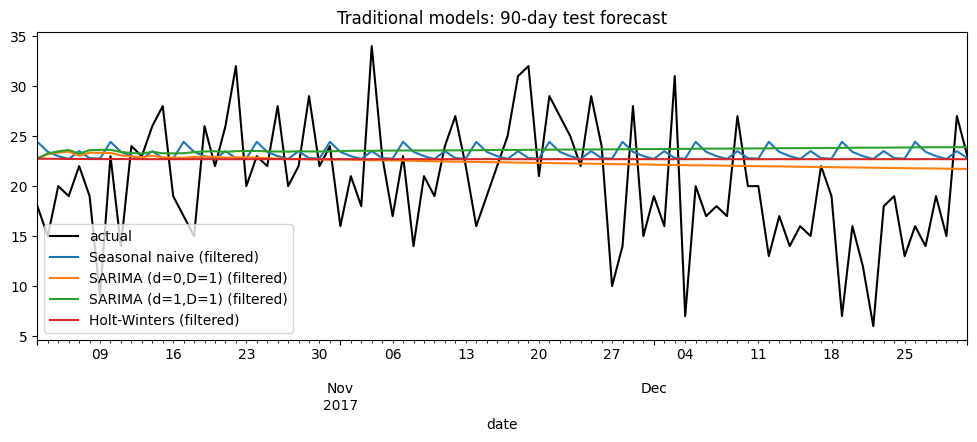

In [3]:
fig, ax = plt.subplots(figsize=(12, 4))
test.plot(ax=ax, color="black", label="actual")
for k in ["Seasonal naive (filtered)", "SARIMA (d=0,D=1) (filtered)",
          "SARIMA (d=1,D=1) (filtered)", "Holt-Winters (filtered)"]:
    pd.Series(preds[k], index=test.index).plot(ax=ax, label=k)
ax.legend(); ax.set_title("Traditional models: 90-day test forecast")
plt.savefig("../outputs/04_traditional_forecast.png", dpi=150)